# 04 – Modelling: Baseline and Three Alternatives
**IT3091 Machine Learning · Group 2026-DS-02 · Bank Marketing**

| Model | Role | Why this model |
|---|---|---|
| **Logistic Regression** | **Baseline** (D2) | Simple, fast, interpretable coefficients; standard reference for binary classification |
| Decision Tree | Alternative 1 | Captures non-linear effects and interactions; produces readable rules for marketing profiles |
| Random Forest | Alternative 2 | Many de-correlated trees, so it is more stable and accurate than one tree; robust to outliers and collinearity |
| XGBoost | Alternative 3 | Gradient boosting, typically the strongest family on tabular data; built-in imbalance handling |

**Rules (from Steps 3–4):** each model is a full `Pipeline` (preprocessing + model), tuned with the **same 5 CV folds** (`ev.CV`)
on the **training set only**, scored by **PR-AUC**. Class weights handle imbalance (D16). The test set is **not used** here.

| Section | Content |
|---|---|
| 1 | Setup |
| 2 | Tuning: Logistic Regression (baseline) |
| 3 | Tuning: Decision Tree |
| 4 | Tuning: Random Forest |
| 5 | Tuning: XGBoost |
| 6 | Model comparison (all metrics, same folds) |
| 7 | Overfitting check |
| 8 | Imbalance strategy check: SMOTE vs class weights |
| 9 | Save models and results |
| 10 | Summary |

⏱ **Runtime ≈ 15–25 minutes** (Random Forest and XGBoost tuning train a few hundred models).

*Parallelism note:* the searches run their folds one after another (`n_jobs` not set), while Random Forest and XGBoost use all
CPU cores internally (`n_jobs=-1`, thread-based). Process-based parallel search (`GridSearchCV(n_jobs=-1)`) crashes with the
installed joblib 1.5.1 on Windows/Python 3.13, and thread-based parallelism inside the models avoids that problem.

## 1. Setup

In [1]:
import sys, json, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import config
from src import preprocessing as prep
from src import evaluation as ev

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)
config.MODELS_DIR.mkdir(exist_ok=True)
config.RESULTS_DIR.mkdir(exist_ok=True)

X_train, X_test, y_train, y_test = prep.load_split()
del X_test, y_test   # test set stays locked until Step 6
SCALE_POS_WEIGHT = (y_train == 0).sum() / (y_train == 1).sum()
print("Training set:", X_train.shape, f"| yes-rate {y_train.mean():.2%} | scale_pos_weight {SCALE_POS_WEIGHT:.2f}")

Training set: (32940, 19) | yes-rate 11.27% | scale_pos_weight 7.88


In [3]:
searches = {}   # fitted search objects, one per model

def run_search(name, search):
    """Fit a hyperparameter search on the training set and report the best result."""
    start = time.time()
    search.fit(X_train, y_train)
    searches[name] = search
    best = search.cv_results_
    i = search.best_index_
    print(f"{name}: {len(best['params'])} settings x {search.n_splits_} folds in {time.time() - start:.0f}s")
    print(f"  best CV PR-AUC = {best['mean_test_score'][i]:.4f} ± {best['std_test_score'][i]:.4f}")
    print(f"  best params    = {search.best_params_}")
    return search

def top_results(search, n=5):
    """The n best settings of a search: parameters, CV score and training score."""
    res = pd.DataFrame(search.cv_results_)
    cols = ["params", "mean_test_score", "std_test_score", "mean_train_score", "rank_test_score"]
    return (res[cols].sort_values("rank_test_score").head(n)
            .rename(columns={"mean_test_score": "cv_pr_auc", "std_test_score": "cv_std",
                             "mean_train_score": "train_pr_auc"}).round(4))

## 2. Logistic Regression: baseline
Linear pipeline (one-hot, age groups, scaled numerics, reduced economic indicators; see `02_preprocessing`).
**Tuned:** `C` = inverse regularisation strength. Small C = strong regularisation (simpler model, coefficients pulled towards 0);
large C = weak regularisation.

In [4]:
lr_pipe = Pipeline([
    ("prep", prep.build_preprocessor("linear")),
    ("model", LogisticRegression(class_weight="balanced", max_iter=5000)),
])
lr_grid = {"model__C": [0.001, 0.01, 0.1, 1, 10, 100]}
run_search("Logistic Regression", GridSearchCV(
    lr_pipe, lr_grid, scoring="average_precision", cv=ev.CV, return_train_score=True))
top_results(searches["Logistic Regression"], n=6)

Logistic Regression: 6 settings x 5 folds in 21s
  best CV PR-AUC = 0.4376 ± 0.0125
  best params    = {'model__C': 0.01}


,params,cv_pr_auc,cv_std,train_pr_auc,rank_test_score
1,{'model__C': 0.01},0.4376,0.0125,0.4399,1
2,{'model__C': 0.1},0.4373,0.0130,0.4405,2
3,{'model__C': 1},0.4368,0.0131,0.4402,3
5,{'model__C': 100},0.4368,0.0131,0.4402,4
4,{'model__C': 10},0.4367,0.0131,0.4402,5
0,{'model__C': 0.001},0.4173,0.0068,0.4186,6


## 3. Decision Tree: alternative 1
Tree pipeline (one-hot, raw numerics, all economic indicators). A single tree overfits easily, so the tuning focuses on **limiting its size**:
- `max_depth`: maximum number of questions from root to leaf
- `min_samples_leaf`: minimum clients in each final group (larger = smoother, more reliable rates)
- `criterion`: how split quality is measured (Gini vs entropy)

In [5]:
dt_pipe = Pipeline([
    ("prep", prep.build_preprocessor("tree")),
    ("model", DecisionTreeClassifier(class_weight="balanced", random_state=config.RANDOM_STATE)),
])
dt_grid = {
    "model__max_depth": [3, 4, 5, 6, 8, 10, 12, None],
    "model__min_samples_leaf": [1, 10, 50, 100, 200],
    "model__criterion": ["gini", "entropy"],
}
run_search("Decision Tree", GridSearchCV(
    dt_pipe, dt_grid, scoring="average_precision", cv=ev.CV, return_train_score=True))
top_results(searches["Decision Tree"])

Decision Tree: 80 settings x 5 folds in 147s
  best CV PR-AUC = 0.4433 ± 0.0156
  best params    = {'model__criterion': 'entropy', 'model__max_depth': None, 'model__min_samples_leaf': 100}


,params,cv_pr_auc,cv_std,train_pr_auc,rank_test_score
78,"{'model__criterion': 'entropy', 'model__max_depth': None, 'model__min_samples_leaf': 100}",0.4433,0.0156,0.4784,1
38,"{'model__criterion': 'gini', 'model__max_depth': None, 'model__min_samples_leaf': 100}",0.4409,0.0154,0.4787,2
73,"{'model__criterion': 'entropy', 'model__max_depth': 12, 'model__min_samples_leaf': 100}",0.4405,0.0153,0.4708,3
68,"{'model__criterion': 'entropy', 'model__max_depth': 10, 'model__min_samples_leaf': 100}",0.4393,0.0156,0.4662,4
79,"{'model__criterion': 'entropy', 'model__max_depth': None, 'model__min_samples_leaf': 200}",0.4388,0.0176,0.4551,5


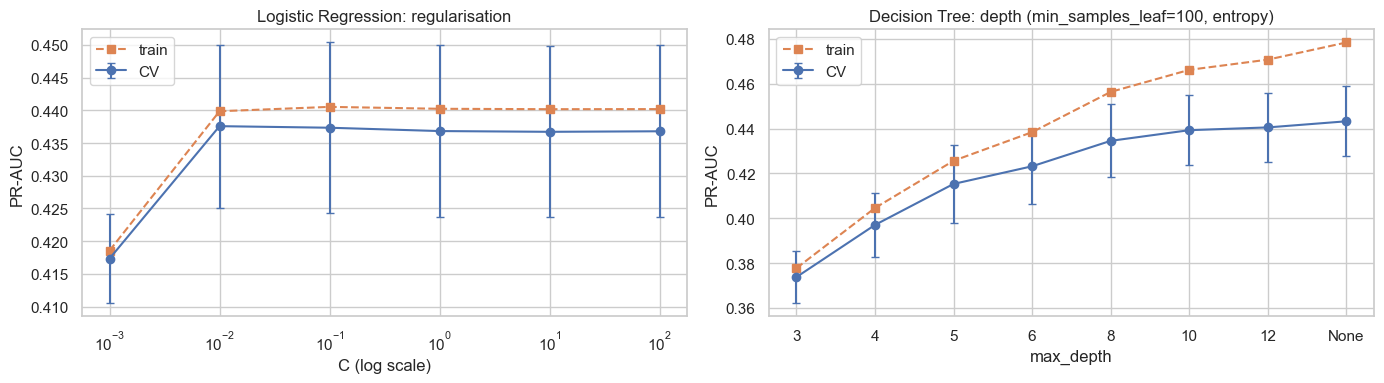

In [6]:
# Tuning curves: how the CV score changes with model complexity (train vs CV shows over/under-fitting)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

lr_res = pd.DataFrame(searches["Logistic Regression"].cv_results_)
axes[0].errorbar(lr_res["param_model__C"].astype(float), lr_res["mean_test_score"], yerr=lr_res["std_test_score"],
                 marker="o", capsize=3, label="CV")
axes[0].plot(lr_res["param_model__C"].astype(float), lr_res["mean_train_score"], marker="s", ls="--", label="train")
axes[0].set_xscale("log")
axes[0].set(xlabel="C (log scale)", ylabel="PR-AUC", title="Logistic Regression: regularisation")
axes[0].legend()

dt_res = pd.DataFrame(searches["Decision Tree"].cv_results_)
best_dt = searches["Decision Tree"].best_params_
sub = dt_res[(dt_res["param_model__min_samples_leaf"] == best_dt["model__min_samples_leaf"]) &
             (dt_res["param_model__criterion"] == best_dt["model__criterion"])].copy()
sub["depth"] = sub["param_model__max_depth"].astype(object).fillna("None").astype(str)
axes[1].errorbar(sub["depth"], sub["mean_test_score"], yerr=sub["std_test_score"], marker="o", capsize=3, label="CV")
axes[1].plot(sub["depth"], sub["mean_train_score"], marker="s", ls="--", label="train")
axes[1].set(xlabel="max_depth", ylabel="PR-AUC",
            title=f"Decision Tree: depth (min_samples_leaf={best_dt['model__min_samples_leaf']}, {best_dt['model__criterion']})")
axes[1].legend()
plt.tight_layout()
plt.savefig(config.FIGURES / "fig12_tuning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Random Forest: alternative 2
The search space is too large for a full grid, so **randomised search** tries 20 random combinations (same seed, so reproducible).
- `n_estimators`: number of trees
- `max_depth`, `min_samples_leaf`: size of each tree
- `max_features`: share of features each split may consider (lower = more diverse trees)
- `class_weight`: `balanced` (whole training set) or `balanced_subsample` (re-computed per bootstrap sample)

In [7]:
rf_pipe = Pipeline([
    ("prep", prep.build_preprocessor("tree")),
    ("model", RandomForestClassifier(random_state=config.RANDOM_STATE, n_jobs=-1)),
])
rf_space = {
    "model__n_estimators": [200, 300, 500],
    "model__max_depth": [8, 12, 16, 20, None],
    "model__min_samples_leaf": [1, 3, 5, 10, 20],
    "model__max_features": ["sqrt", 0.3, 0.5],
    "model__class_weight": ["balanced", "balanced_subsample"],
}
run_search("Random Forest", RandomizedSearchCV(
    rf_pipe, rf_space, n_iter=20, scoring="average_precision", cv=ev.CV,
    return_train_score=True, random_state=config.RANDOM_STATE))
top_results(searches["Random Forest"])

Random Forest: 20 settings x 5 folds in 1526s
  best CV PR-AUC = 0.4702 ± 0.0176
  best params    = {'model__n_estimators': 300, 'model__min_samples_leaf': 10, 'model__max_features': 0.3, 'model__max_depth': 12, 'model__class_weight': 'balanced'}


,params,cv_pr_auc,cv_std,train_pr_auc,rank_test_score
12,"{'model__n_estimators': 300, 'model__min_samples_leaf': 10, 'model__max_features': 0.3, 'model__max_depth': 12, 'mod...",0.4702,0.0176,0.5900,1
6,"{'model__n_estimators': 300, 'model__min_samples_leaf': 10, 'model__max_features': 'sqrt', 'model__max_depth': 16, '...",0.4700,0.0189,0.5876,2
9,"{'model__n_estimators': 200, 'model__min_samples_leaf': 20, 'model__max_features': 0.3, 'model__max_depth': 12, 'mod...",0.4695,0.0173,0.5493,3
17,"{'model__n_estimators': 300, 'model__min_samples_leaf': 10, 'model__max_features': 'sqrt', 'model__max_depth': 12, '...",0.4690,0.0175,0.5573,4
2,"{'model__n_estimators': 200, 'model__min_samples_leaf': 20, 'model__max_features': 0.3, 'model__max_depth': 16, 'mod...",0.4688,0.0175,0.5691,5


## 5. XGBoost: alternative 3
Gradient boosting builds trees **one after another**, each correcting the errors of the previous ones. Randomised search, 25 combinations.
- `learning_rate` × `n_estimators`: step size and number of boosting rounds (smaller steps need more rounds)
- `max_depth`, `min_child_weight`: tree size / minimum evidence per leaf
- `subsample`, `colsample_bytree`: random share of rows / features per tree (reduces overfitting)
- `gamma`, `reg_lambda`: regularisation
- `scale_pos_weight` is **fixed** at no/yes ≈ 7.88 (class-weight strategy, D16).

In [8]:
xgb_pipe = Pipeline([
    ("prep", prep.build_preprocessor("tree")),
    ("model", XGBClassifier(objective="binary:logistic", eval_metric="aucpr", tree_method="hist",
                            scale_pos_weight=SCALE_POS_WEIGHT, random_state=config.RANDOM_STATE, n_jobs=-1)),
])
xgb_space = {
    "model__n_estimators": [200, 400, 600, 800],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__max_depth": [3, 4, 5, 6],
    "model__min_child_weight": [1, 3, 5, 10],
    "model__subsample": [0.7, 0.8, 1.0],
    "model__colsample_bytree": [0.6, 0.8, 1.0],
    "model__gamma": [0, 1],
    "model__reg_lambda": [1, 5],
}
run_search("XGBoost", RandomizedSearchCV(
    xgb_pipe, xgb_space, n_iter=25, scoring="average_precision", cv=ev.CV,
    return_train_score=True, random_state=config.RANDOM_STATE))
top_results(searches["XGBoost"])

XGBoost: 25 settings x 5 folds in 490s
  best CV PR-AUC = 0.4674 ± 0.0166
  best params    = {'model__subsample': 0.7, 'model__reg_lambda': 1, 'model__n_estimators': 600, 'model__min_child_weight': 5, 'model__max_depth': 5, 'model__learning_rate': 0.01, 'model__gamma': 0, 'model__colsample_bytree': 1.0}


,params,cv_pr_auc,cv_std,train_pr_auc,rank_test_score
20,"{'model__subsample': 0.7, 'model__reg_lambda': 1, 'model__n_estimators': 600, 'model__min_child_weight': 5, 'model__...",0.4674,0.0166,0.5327,1
24,"{'model__subsample': 0.8, 'model__reg_lambda': 1, 'model__n_estimators': 400, 'model__min_child_weight': 3, 'model__...",0.4669,0.0168,0.5248,2
22,"{'model__subsample': 1.0, 'model__reg_lambda': 1, 'model__n_estimators': 600, 'model__min_child_weight': 5, 'model__...",0.4665,0.0142,0.5465,3
16,"{'model__subsample': 0.7, 'model__reg_lambda': 1, 'model__n_estimators': 600, 'model__min_child_weight': 10, 'model_...",0.4665,0.0168,0.5265,4
13,"{'model__subsample': 0.7, 'model__reg_lambda': 5, 'model__n_estimators': 400, 'model__min_child_weight': 3, 'model__...",0.4660,0.0153,0.5399,5


## 6. Model comparison
Each tuned model is cross-validated again with **all** metrics on the same 5 folds, together with the reference floor.
Recall / precision / F1 / accuracy use the default 0.5 threshold; the threshold is tuned in Step 6 (evaluation).

In [9]:
MODEL_ORDER = ["Logistic Regression", "Decision Tree", "Random Forest", "XGBoost"]
candidates = {
    "Dummy: always no": Pipeline([("prep", prep.build_preprocessor("tree")),
                                  ("model", DummyClassifier(strategy="most_frequent"))]),
    "Dummy: random guess": Pipeline([("prep", prep.build_preprocessor("tree")),
                                     ("model", DummyClassifier(strategy="stratified", random_state=config.RANDOM_STATE))]),
    **{name: clone(searches[name].best_estimator_) for name in MODEL_ORDER},
}
cv_rows = []
for name, model in candidates.items():
    start = time.time()
    cv_rows.append(ev.evaluate_cv(model, X_train, y_train, name))
    print(f"{name:22s} done in {time.time() - start:.0f}s")
comparison = ev.cv_table(cv_rows)
comparison

Dummy: always no       done in 1s
Dummy: random guess    done in 1s
Logistic Regression    done in 5s
Decision Tree          done in 4s
Random Forest          done in 71s
XGBoost                done in 27s


,pr_auc,roc_auc,recall,precision,f1,balanced_acc,accuracy,top20_capture
model,,,,,,,,
Dummy: always no,0.113 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.887 ± 0.000,0.189 ± 0.005
Dummy: random guess,0.113 ± 0.001,0.502 ± 0.004,0.114 ± 0.006,0.115 ± 0.006,0.115 ± 0.006,0.502 ± 0.004,0.802 ± 0.001,0.199 ± 0.009
Logistic Regression,0.438 ± 0.012,0.787 ± 0.007,0.634 ± 0.014,0.328 ± 0.012,0.432 ± 0.013,0.735 ± 0.009,0.812 ± 0.007,0.620 ± 0.014
Decision Tree,0.443 ± 0.016,0.783 ± 0.005,0.652 ± 0.011,0.315 ± 0.016,0.425 ± 0.015,0.736 ± 0.008,0.800 ± 0.012,0.625 ± 0.013
Random Forest,0.470 ± 0.018,0.801 ± 0.010,0.603 ± 0.013,0.411 ± 0.012,0.489 ± 0.012,0.747 ± 0.007,0.858 ± 0.004,0.643 ± 0.014
XGBoost,0.467 ± 0.017,0.800 ± 0.008,0.631 ± 0.011,0.372 ± 0.010,0.468 ± 0.010,0.748 ± 0.007,0.838 ± 0.004,0.642 ± 0.012


In [10]:
print("Paired comparison with the baseline (Logistic Regression), fold by fold on PR-AUC:")
ev.paired_comparison([r for r in cv_rows if r["model"] in MODEL_ORDER], baseline="Logistic Regression").round(4)

Paired comparison with the baseline (Logistic Regression), fold by fold on PR-AUC:


,mean_pr_auc_diff_vs_baseline,std_of_diff,folds_better
model,,,
Decision Tree,0.0057,0.0084,3/5
Random Forest,0.0326,0.0086,5/5
XGBoost,0.0298,0.0064,5/5


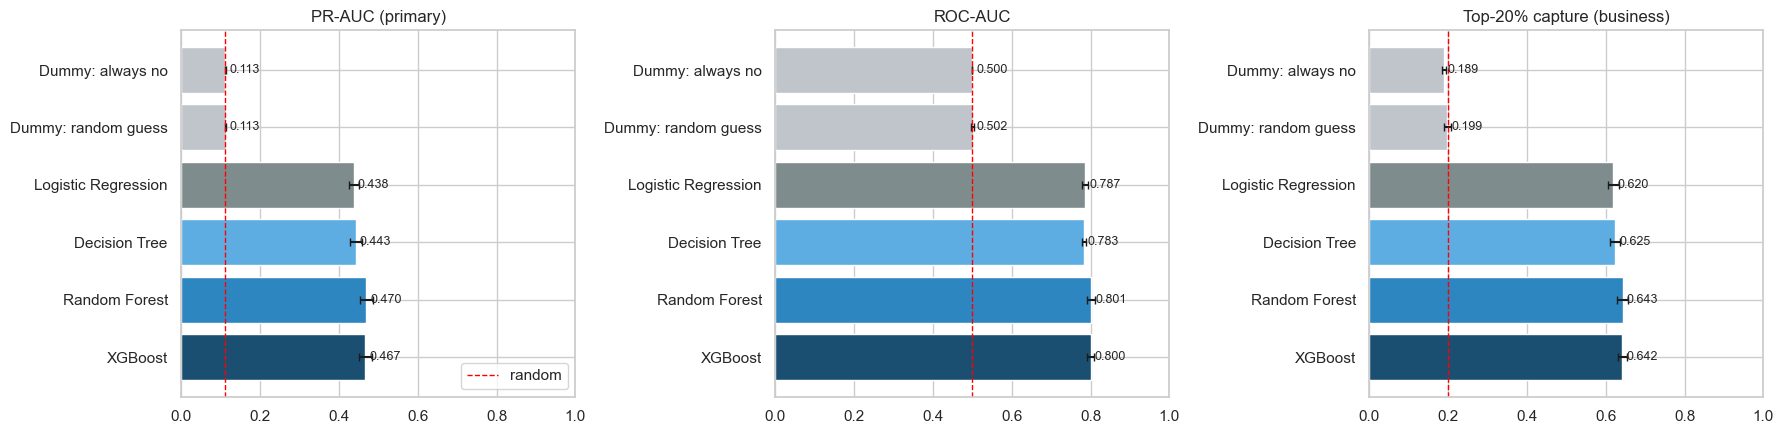

In [11]:
cv_df = pd.DataFrame(cv_rows).drop(columns="fold_scores").set_index("model")
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
palette = ["#c0c5cc", "#c0c5cc", "#7f8c8d", "#5dade2", "#2e86c1", "#1b4f72"]
for ax, (metric, title, ref) in zip(axes, [
        ("pr_auc", "PR-AUC (primary)", y_train.mean()),
        ("roc_auc", "ROC-AUC", 0.5),
        ("top20_capture", "Top-20% capture (business)", 0.2)]):
    ax.barh(cv_df.index, cv_df[f"{metric}_mean"], xerr=cv_df[f"{metric}_std"], color=palette, capsize=3)
    ax.axvline(ref, color="red", ls="--", lw=1, label="random")
    for yi, v in enumerate(cv_df[f"{metric}_mean"]):
        ax.text(v + 0.01, yi, f"{v:.3f}", va="center", fontsize=9)
    ax.set_title(title)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.savefig(config.FIGURES / "fig13_model_comparison_cv.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Overfitting check
Training PR-AUC vs cross-validated PR-AUC for each model's best setting. A large gap means the model memorises the training data
instead of learning patterns that generalise.

In [12]:
rows = []
for name in MODEL_ORDER:
    s = searches[name]
    i = s.best_index_
    train_score = s.cv_results_["mean_train_score"][i]
    cv_score = s.cv_results_["mean_test_score"][i]
    rows.append({"model": name, "train_pr_auc": round(train_score, 4), "cv_pr_auc": round(cv_score, 4),
                 "gap": round(train_score - cv_score, 4),
                 "gap_%_of_cv": round(100 * (train_score - cv_score) / cv_score, 1)})
overfit = pd.DataFrame(rows).set_index("model")
overfit

,train_pr_auc,cv_pr_auc,gap,gap_%_of_cv
model,,,,
Logistic Regression,0.4399,0.4376,0.0023,0.5
Decision Tree,0.4784,0.4433,0.0352,7.9
Random Forest,0.5900,0.4702,0.1198,25.5
XGBoost,0.5327,0.4674,0.0653,14.0


## 8. Imbalance strategy check: SMOTE vs class weights (completes D16)
Each tuned model is re-run with **SMOTE** (synthetic "yes" clients, created inside each training fold only via an `imblearn` pipeline)
**instead of** class weights. Note: SMOTE interpolates between neighbours, so on one-hot columns it creates fractional "half-category"
values. This is a known weakness of SMOTE on categorical data.

In [13]:
def smote_version(name):
    best = searches[name].best_estimator_
    model = clone(best.named_steps["model"])
    if name == "XGBoost":
        model.set_params(scale_pos_weight=1)
    else:
        model.set_params(class_weight=None)
    return ImbPipeline([("prep", clone(best.named_steps["prep"])),
                        ("smote", SMOTE(random_state=config.RANDOM_STATE)),
                        ("model", model)])

smote_rows = []
for name in MODEL_ORDER:
    start = time.time()
    smote_rows.append(ev.evaluate_cv(smote_version(name), X_train, y_train, f"{name} + SMOTE"))
    print(f"{name:20s} + SMOTE done in {time.time() - start:.0f}s")

cw = pd.DataFrame([r for r in cv_rows if r["model"] in MODEL_ORDER]).set_index("model")
sm = pd.DataFrame(smote_rows).assign(model=lambda d: d["model"].str.replace(" + SMOTE", "", regex=False)).set_index("model")
imbalance_compare = pd.DataFrame({
    "PR-AUC class weights": cw["pr_auc_mean"], "PR-AUC SMOTE": sm["pr_auc_mean"],
    "recall class weights": cw["recall_mean"], "recall SMOTE": sm["recall_mean"],
    "precision class weights": cw["precision_mean"], "precision SMOTE": sm["precision_mean"],
    "top20 class weights": cw["top20_capture_mean"], "top20 SMOTE": sm["top20_capture_mean"],
    "fit time (s) class weights": cw["fit_time_s"], "fit time (s) SMOTE": sm["fit_time_s"],
}).round(4)
imbalance_compare

Logistic Regression  + SMOTE done in 9s
Decision Tree        + SMOTE done in 11s
Random Forest        + SMOTE done in 186s
XGBoost              + SMOTE done in 118s


,PR-AUC class weights,PR-AUC SMOTE,recall class weights,recall SMOTE,precision class weights,precision SMOTE,top20 class weights,top20 SMOTE,fit time (s) class weights,fit time (s) SMOTE
model,,,,,,,,,,
Logistic Regression,0.4376,0.4378,0.6343,0.6341,0.3279,0.3255,0.6195,0.6182,0.7391,1.5059
Decision Tree,0.4433,0.3815,0.6524,0.4452,0.3150,0.4129,0.6249,0.5780,0.6358,1.9970
Random Forest,0.4702,0.4433,0.6028,0.4646,0.4114,0.4862,0.6430,0.6303,12.8509,35.7625
XGBoost,0.4674,0.4481,0.6314,0.3888,0.3721,0.5183,0.6421,0.6257,5.0462,23.2673


## 9. Save models and results
Each search already re-fitted its best pipeline on the **full training set** (`refit=True`). These fitted pipelines are saved, so
Step 6 can evaluate them on the test set without retraining.

In [14]:
saved = {}
for name in MODEL_ORDER:
    path = config.MODELS_DIR / f"{name.lower().replace(' ', '_')}.joblib"
    joblib.dump(searches[name].best_estimator_, path)
    saved[name] = path.name

best_params = {name: {k.replace("model__", ""): (v if not isinstance(v, np.generic) else v.item())
                      for k, v in searches[name].best_params_.items()} for name in MODEL_ORDER}
(config.RESULTS_DIR / "best_params.json").write_text(json.dumps(best_params, indent=2, default=str))

pd.DataFrame(cv_rows + smote_rows).drop(columns="fold_scores").to_csv(config.RESULTS_DIR / "cv_comparison.csv", index=False)
overfit.to_csv(config.RESULTS_DIR / "overfitting_check.csv")
for name in MODEL_ORDER:
    top_results(searches[name], n=10).to_csv(config.RESULTS_DIR / f"tuning_{name.lower().replace(' ', '_')}.csv", index=False)

print("Saved models:", saved)
print("Saved results:", sorted(p.name for p in config.RESULTS_DIR.iterdir()))
print(json.dumps(best_params, indent=2, default=str))

Saved models: {'Logistic Regression': 'logistic_regression.joblib', 'Decision Tree': 'decision_tree.joblib', 'Random Forest': 'random_forest.joblib', 'XGBoost': 'xgboost.joblib'}
Saved results: ['best_params.json', 'cv_comparison.csv', 'overfitting_check.csv', 'tuning_decision_tree.csv', 'tuning_logistic_regression.csv', 'tuning_random_forest.csv', 'tuning_xgboost.csv']
{
  "Logistic Regression": {
    "C": 0.01
  },
  "Decision Tree": {
    "criterion": "entropy",
    "max_depth": null,
    "min_samples_leaf": 100
  },
  "Random Forest": {
    "n_estimators": 300,
    "min_samples_leaf": 10,
    "max_features": 0.3,
    "max_depth": 12,
    "class_weight": "balanced"
  },
  "XGBoost": {
    "subsample": 0.7,
    "reg_lambda": 1,
    "n_estimators": 600,
    "min_child_weight": 5,
    "max_depth": 5,
    "learning_rate": 0.01,
    "gamma": 0,
    "colsample_bytree": 1.0
  }
}


## 10. Summary
Full details: `docs/modelling_findings.txt` and `docs/model_comparison.md`.

**Tuned models, 5-fold CV on the training set (mean ± std)**
| Model | PR-AUC | ROC-AUC | Recall | Precision | F1 | Top-20% capture | vs baseline (PR-AUC, folds better) |
|---|---|---|---|---|---|---|---|
| Random guess | 0.113 | 0.502 | 0.114 | 0.115 | 0.115 | 0.199 | – |
| **Logistic Regression (baseline)** | 0.438 ± 0.012 | 0.787 | 0.634 | 0.328 | 0.432 | 0.620 | – |
| Decision Tree | 0.443 ± 0.016 | 0.783 | 0.652 | 0.315 | 0.425 | 0.625 | +0.006, 3/5 |
| **Random Forest** | **0.470 ± 0.018** | **0.801** | 0.603 | **0.411** | **0.489** | **0.643** | **+0.033, 5/5** |
| **XGBoost** | 0.467 ± 0.017 | 0.800 | 0.631 | 0.372 | 0.468 | 0.642 | **+0.030, 5/5** |

**Findings**
- **Random Forest and XGBoost beat the baseline in all 5 folds** (+0.033 / +0.030 PR-AUC; the fold-to-fold std of the difference is only 0.009 / 0.006, so the gain is consistent, not luck). The Decision Tree is **not reliably better** than the baseline (+0.006, better in only 3/5 folds).
- **RF vs XGBoost is effectively a tie** (0.470 vs 0.467, a difference far below the fold std of ≈ 0.017). At the default 0.5 threshold RF favours precision (0.41) and XGBoost recall (0.63); this trade-off is set by threshold tuning in Step 6.
- **Business value:** the best models find **≈ 64% of subscribers in the top-scored 20% of clients**, 3.2× random calling.
- **Tuning gains were small** (LR 0.437 → 0.438, RF 0.465 → 0.470 vs the untuned versions in `03_validation`), and the top-5 settings of RF and XGBoost lie within ≈ 0.002 of each other. The optimum is flat, so results are not sensitive to exact hyperparameters, and performance appears limited by the information in the pre-call features (≈ 0.47 PR-AUC ceiling) rather than by the model choice.
- **Tuning curves (fig12):** LR is stable for C ≥ 0.01 and only very strong regularisation (C = 0.001) hurts. For the Decision Tree, CV PR-AUC rises with depth but flattens after ≈ 10 while the train–CV gap widens; tree size is effectively controlled by `min_samples_leaf = 100`.
- **Overfitting:** train–CV gap LR 0.5%, DT 7.9%, XGBoost 14.0%, **RF 25.5%** (train 0.59 vs CV 0.47). RF memorises more of the training data, but it still generalises best on CV; XGBoost is the better-regularised of the two.
- **SMOTE never helped (completes D16):** LR unchanged (0.4378 vs 0.4376), DT −0.062, RF −0.027, XGBoost −0.019 PR-AUC, with 2–5× longer fit times. **Class weights are confirmed** as the imbalance strategy.
- **Practical cost:** fit time LR 0.7 s, DT 0.6 s, XGBoost 5.0 s, RF 12.9 s per fold; model size XGBoost 1.5 MB vs RF 21 MB.
- **Shortlist for final selection:** Random Forest and XGBoost, decided in Steps 6–8 using test-set results, threshold analysis, per-year robustness (time drift) and interpretability.